<a href="https://colab.research.google.com/github/JimmyApron/streaming-algorithms/blob/main/streaming_algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STEP 01. 데이터 준비

In [26]:
# 1-1. Colab에서 데이터 다운로드
import urllib.request
import zipfile
from pathlib import Path

# 데이터셋 다운로드
url = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
zip_path = Path("ml-1m.zip")

if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

print("데이터 다운로드 완료")

데이터 다운로드 완료


In [27]:
# 1-2. 스트림 형태로 데이터 읽기
# 데이터를 한 줄씩 읽는 함수
def rating_stream():
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open("ml-1m/ratings.dat") as f:
            for line in f:
                user_id, movie_id, rating, timestamp = (
                    line.decode("utf-8").strip().split("::")
                )

                yield (
                    int(user_id),
                    int(movie_id),
                    int(rating),
                    int(timestamp)
                )

In [28]:
# 1-3. 데이터 확인 및 레코드 수 계산
# 데이터 일부 확인 및 개수 계산
count = 0

for user_id, movie_id, rating, timestamp in rating_stream():
    count += 1

    if count <= 5:
        print(user_id, movie_id, rating, timestamp)

print("전체 레코드 수:", count)

1 1193 5 978300760
1 661 3 978302109
1 914 3 978301968
1 3408 4 978300275
1 2355 5 978824291
전체 레코드 수: 1000209


STEP 02. 알고리즘 구현

In [29]:
# 2-1. Bloom Filter 구현
import hashlib

class BloomFilter:
    def __init__(self, m, k):
        self.m = m
        self.k = k
        self.bits = bytearray((m + 7) // 8)

    # 해시 함수로 비트 배열 인덱스 계산
    def _hashes(self, item):
        data = str(item).encode("utf-8")
        h = hashlib.blake2b(data, digest_size=16).digest()

        h1 = int.from_bytes(h[:8], "big")
        h2 = int.from_bytes(h[8:], "big") or 1

        for i in range(self.k):
            yield (h1 + i * h2) % self.m

    # 데이터 추가
    def add(self, item):
        for idx in self._hashes(item):
            self.bits[idx // 8] |= 1 << (idx % 8)

    # 데이터 포함 여부 확인
    def contains(self, item):
        for idx in self._hashes(item):
            if not (self.bits[idx // 8] & (1 << (idx % 8))):
                return False
        return True

In [30]:
# 데이터 스트림 삽입
import time

# Bloom Filter 생성
bloom = BloomFilter(m=10_000_000, k=7)

start = time.perf_counter()
count = 0

# 평점 데이터를 한 줄씩 삽입
for user_id, movie_id, rating, timestamp in rating_stream():
    key = f"{user_id}:{movie_id}"
    bloom.add(key)
    count += 1

elapsed = time.perf_counter() - start

print("삽입된 데이터 수:", count)
print(f"처리 시간: {elapsed:.4f}초")
print(f"초당 처리량: {count / elapsed:,.0f}건")
print(f"비트 배열 크기: {len(bloom.bits) / 1024**2:.4f} MB")

삽입된 데이터 수: 1000209
처리 시간: 7.5254초
초당 처리량: 132,912건
비트 배열 크기: 1.1921 MB


In [31]:
# 존재하는 평점 기록
test_keys = [
    "1:1193",
    "1:661",
    "1:914",
    "1:3408",
    "1:2355"
]

for key in test_keys:
    print(f"{key}: {bloom.contains(key)}")

1:1193: True
1:661: True
1:914: True
1:3408: True
1:2355: True


In [32]:
# 2-2. Count-Min Sketch 구현
import hashlib
from array import array

class CountMinSketch:
    def __init__(self, width, depth):
        self.width = width
        self.depth = depth
        self.table = [
            array('I', [0]) * width for _ in range(depth)
        ]

    # 각 행에서 사용할 해시 인덱스 계산
    def _hashes(self, item):
        data = str(item).encode("utf-8")
        h = hashlib.blake2b(data, digest_size=16).digest()

        h1 = int.from_bytes(h[:8], "big")
        h2 = int.from_bytes(h[8:], "big") | 1

        for i in range(self.depth):
            yield (h1 + i * h2) % self.width

    # 데이터 등장 횟수 증가
    def add(self, item):
        for i, idx in enumerate(self._hashes(item)):
            self.table[i][idx] += 1

    # 데이터 빈도 추정
    def estimate(self, item):
        return min(
            self.table[i][idx]
            for i, idx in enumerate(self._hashes(item))
        )

In [33]:
# 데이터 스트림 처리
import time
import sys

# Count-Min Sketch 생성
cms = CountMinSketch(width=2000, depth=5)

start = time.perf_counter()
count = 0

# 영화별 평점 횟수 계산
for user_id, movie_id, rating, timestamp in rating_stream():
    cms.add(movie_id)
    count += 1

elapsed_cms = time.perf_counter() - start

# 메모리 사용량 계산
memory = sys.getsizeof(cms.table)
memory += sum(sys.getsizeof(row) for row in cms.table)

print("처리된 데이터 수:", count)
print(f"처리 시간: {elapsed_cms:.4f}초")
print(f"초당 처리량: {count / elapsed_cms:,.0f}건")
print(f"카운터 배열 크기: {memory / 1024:.4f} KiB")

처리된 데이터 수: 1000209
처리 시간: 7.6146초
초당 처리량: 131,355건
카운터 배열 크기: 39.5703 KiB


In [34]:
# 영화별 평점 횟수 추정
test_movies = [1193, 661, 914, 3408, 2355]

for movie_id in test_movies:
    estimated = cms.estimate(movie_id)
    print(f"영화 {movie_id}: {estimated}회")

영화 1193: 1725회
영화 661: 525회
영화 914: 636회
영화 3408: 1315회
영화 2355: 1766회


STEP 03. Ground Truth 계산

In [35]:
# 3-1. Ground Truth 생성
from collections import defaultdict

# Ground Truth 저장
true_pairs = set()
true_counts = defaultdict(int)

user_ids = set()
movie_ids = set()

# 실제 데이터 계산
for user_id, movie_id, rating, timestamp in rating_stream():
    key = f"{user_id}:{movie_id}"

    true_pairs.add(key)
    true_counts[movie_id] += 1

    user_ids.add(user_id)
    movie_ids.add(movie_id)

print("고유 평점 기록 수:", len(true_pairs))
print("사용자 수:", len(user_ids))
print("영화 수:", len(movie_ids))

고유 평점 기록 수: 1000209
사용자 수: 6040
영화 수: 3706


In [36]:
# 3-2. Bloom Filter 정확도 측정
import random

random.seed(42)

users = sorted(user_ids)
movies = sorted(movie_ids)

# 실제 존재하지 않는 기록 100,000개 생성
negative_keys = []
negative_seen = set()

while len(negative_keys) < 100000:
    user_id = random.choice(users)
    movie_id = random.choice(movies)
    key = f"{user_id}:{movie_id}"

    if key not in true_pairs and key not in negative_seen:
        negative_keys.append(key)
        negative_seen.add(key)

# False Positive 계산
fp = 0

for key in negative_keys:
    if bloom.contains(key):
        fp += 1

tn = len(negative_keys) - fp
fpr = fp / len(negative_keys)

print("전체 음성 테스트 수:", len(negative_keys))
print("False Positive:", fp)
print("True Negative:", tn)
print(f"False Positive Rate: {fpr * 100:.4f}%")

전체 음성 테스트 수: 100000
False Positive: 878
True Negative: 99122
False Positive Rate: 0.8780%


In [37]:
# 실제 존재하는 기록 검사
fn = 0

for key in true_pairs:
    if not bloom.contains(key):
        fn += 1

print("전체 양성 테스트 수:", len(true_pairs))
print("False Negative:", fn)
print(f"False Negative Rate: {fn / len(true_pairs) * 100:.4f}%")

전체 양성 테스트 수: 1000209
False Negative: 0
False Negative Rate: 0.0000%


In [38]:
# 3-3. Count-Min Sketch 정확도 측정
# 실제 빈도와 추정 빈도 비교
test_movies = [1193, 661, 914, 3408, 2355]

print("영화 ID | 실제 빈도 | 추정 빈도 | 오차")

for movie_id in test_movies:
    actual = true_counts[movie_id]
    estimated = cms.estimate(movie_id)
    error = estimated - actual

    print(f"{movie_id} | {actual} | {estimated} | {error}")


영화 ID | 실제 빈도 | 추정 빈도 | 오차
1193 | 1725 | 1725 | 0
661 | 525 | 525 | 0
914 | 636 | 636 | 0
3408 | 1315 | 1315 | 0
2355 | 1703 | 1766 | 63


In [39]:
# 3-4. 전체 영화의 평균 오차 계산
errors = []
relative_errors = []

for movie_id, actual in true_counts.items():
    estimated = cms.estimate(movie_id)

    error = abs(estimated - actual)
    relative_error = error / actual

    errors.append(error)
    relative_errors.append(relative_error)

mae = sum(errors) / len(errors)
mape = sum(relative_errors) / len(relative_errors) * 100
max_error = max(errors)

print("전체 영화 수:", len(true_counts))
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}%")
print(f"최대 오차: {max_error}")

전체 영화 수: 3706
MAE: 37.6773
MAPE: 274.2275%
최대 오차: 3428


In [40]:
# Count-Min Sketch 추가 정확도 분석
import statistics

errors = []
relative_errors = []

for movie_id, actual in true_counts.items():
    estimated = cms.estimate(movie_id)
    error = abs(estimated - actual)

    errors.append(error)
    relative_errors.append(error / actual)

# 추가 정확도 지표 계산
median_error = statistics.median(errors)
exact_count = sum(1 for e in errors if e == 0)
exact_rate = exact_count / len(errors) * 100
wape = sum(errors) / sum(true_counts.values()) * 100

print(f"중앙값 오차: {median_error:.4f}")
print(f"정확하게 추정한 영화 수: {exact_count}개")
print(f"정확한 추정 비율: {exact_rate:.2f}%")
print(f"WAPE: {wape:.4f}%")


중앙값 오차: 0.0000
정확하게 추정한 영화 수: 2168개
정확한 추정 비율: 58.50%
WAPE: 13.9603%


STEP 04. 메모리 및 처리시간 비교

In [41]:
# 4-1. 메모리 사용량 측정
import sys

# Bloom Filter 메모리
bloom_memory = sys.getsizeof(bloom.bits)

# Count-Min Sketch 메모리
cms_memory = sys.getsizeof(cms.table)
cms_memory += sum(sys.getsizeof(row) for row in cms.table)

# set 메모리 (문자열 데이터 포함)
set_memory = sys.getsizeof(true_pairs)
set_memory += sum(sys.getsizeof(key) for key in true_pairs)

# dictionary 메모리 (키와 값 포함)
dict_memory = sys.getsizeof(true_counts)
dict_memory += sum(
    sys.getsizeof(k) + sys.getsizeof(v)
    for k, v in true_counts.items()
)

# MiB 단위 출력
def to_mib(size):
    return size / (1024 ** 2)

print("[Bloom Filter vs Set]")
print(f"Bloom Filter: {to_mib(bloom_memory):.4f} MiB")
print(f"Set: {to_mib(set_memory):.4f} MiB")
print(f"메모리 절감률: {(1 - bloom_memory / set_memory) * 100:.2f}%")

print("\n[Count-Min Sketch vs Dictionary]")
print(f"Count-Min Sketch: {to_mib(cms_memory):.4f} MiB")
print(f"Dictionary: {to_mib(dict_memory):.4f} MiB")
print(f"메모리 절감률: {(1 - cms_memory / dict_memory) * 100:.2f}%")

[Bloom Filter vs Set]
Bloom Filter: 1.1921 MiB
Set: 79.2656 MiB
메모리 절감률: 98.50%

[Count-Min Sketch vs Dictionary]
Count-Min Sketch: 0.0386 MiB
Dictionary: 0.3386 MiB
메모리 절감률: 88.59%


In [17]:
# 4-2. 처리시간 반복 측정
import time
import statistics

# 알고리즘별 처리시간 측정
def measure_time(algorithm, repeats=3):
    times = []
    count = 0

    for _ in range(repeats):
        if algorithm == "Bloom Filter":
            model = BloomFilter(m=10_000_000, k=7)
        else:
            model = CountMinSketch(width=2000, depth=5)

        start = time.perf_counter()
        count = 0

        for user_id, movie_id, rating, timestamp in rating_stream():
            if algorithm == "Bloom Filter":
                model.add(f"{user_id}:{movie_id}")
            else:
                model.add(movie_id)

            count += 1

        times.append(time.perf_counter() - start)

    avg_time = statistics.mean(times)
    throughput = count / avg_time

    print(f"\n[{algorithm}]")
    print("반복 실행 시간:", [round(t, 4) for t in times])
    print(f"평균 처리시간: {avg_time:.4f}초")
    print(f"초당 처리량: {throughput:,.0f}건")

    return avg_time, throughput


# 각 알고리즘 3회씩 측정
bf_time, bf_throughput = measure_time("Bloom Filter")
cms_time, cms_throughput = measure_time("Count-Min Sketch")



[Bloom Filter]
반복 실행 시간: [8.6215, 6.9117, 9.2091]
평균 처리시간: 8.2474초
초당 처리량: 121,275건

[Count-Min Sketch]
반복 실행 시간: [5.92, 7.3499, 5.7932]
평균 처리시간: 6.3544초
초당 처리량: 157,405건


STEP 05. 파라미터 비교 실험

In [18]:
# 공통 측정 함수
import time
import sys
import math
import statistics
import pandas as pd

# 각 설정의 처리시간을 3회 측정
def run_stream_test(create_model, add_data, repeats=3):
    times = []
    last_model = None
    count = 0

    for _ in range(repeats):
        model = create_model()
        count = 0
        start = time.perf_counter()

        for user_id, movie_id, rating, timestamp in rating_stream():
            add_data(model, user_id, movie_id)
            count += 1

        times.append(time.perf_counter() - start)
        last_model = model

    avg_time = statistics.mean(times)

    return last_model, avg_time, count / avg_time


In [19]:
# Bloom Filter 파라미터 실험
def test_bloom(m, k):
    model, avg_time, throughput = run_stream_test(
        lambda: BloomFilter(m, k),
        lambda bf, u, movie: bf.add(f"{u}:{movie}")
    )

    # 실제 FPR 계산
    fp = sum(model.contains(key) for key in negative_keys)
    fpr = fp / len(negative_keys) * 100

    # 이론적 FPR 계산
    n = len(true_pairs)
    theoretical_fpr = (1 - math.exp(-k * n / m)) ** k * 100

    memory = sys.getsizeof(model.bits) / (1024 ** 2)

    return {
        "m": m,
        "k": k,
        "FPR(%)": fpr,
        "이론 FPR(%)": theoretical_fpr,
        "메모리(MiB)": memory,
        "평균시간(s)": avg_time,
        "처리량(건/s)": throughput
    }


# 동일 설정의 중복 실행 방지
bf_cache = {}

def get_bloom_result(m, k):
    if (m, k) not in bf_cache:
        bf_cache[(m, k)] = test_bloom(m, k)
    return bf_cache[(m, k)]


# 실험 1: 비트 배열 크기 변경
bf_m_results = []

for m in [5_000_000, 7_500_000, 10_000_000, 15_000_000, 20_000_000]:
    print(f"Bloom Filter m={m:,} 실험 중")
    bf_m_results.append(get_bloom_result(m, 7))

# 실험 2: 해시 함수 개수 변경
bf_k_results = []

for k in [2, 4, 7, 10, 14]:
    print(f"Bloom Filter k={k} 실험 중")
    bf_k_results.append(get_bloom_result(10_000_000, k))

print("\n[비트 배열 크기 비교]")
display(pd.DataFrame(bf_m_results).round(4))

print("\n[해시 함수 개수 비교]")
display(pd.DataFrame(bf_k_results).round(4))

Bloom Filter m=5,000,000 실험 중
Bloom Filter m=7,500,000 실험 중
Bloom Filter m=10,000,000 실험 중
Bloom Filter m=15,000,000 실험 중
Bloom Filter m=20,000,000 실험 중
Bloom Filter k=2 실험 중
Bloom Filter k=4 실험 중
Bloom Filter k=7 실험 중
Bloom Filter k=10 실험 중
Bloom Filter k=14 실험 중

[비트 배열 크기 비교]


,m,k,FPR(%),이론 FPR(%),메모리(MiB),평균시간(s),처리량(건/s)
0,5000000,7,13.840,13.7874,0.5961,7.9905,125173.9950
1,7500000,7,3.100,3.0304,0.8941,8.0093,124881.1482
2,10000000,7,0.878,0.8202,1.1921,7.9738,125436.8585
3,15000000,7,0.090,0.1004,1.7882,7.5758,132026.0022
4,20000000,7,0.022,0.0196,2.3842,7.9553,125728.9379



[해시 함수 개수 비교]


,m,k,FPR(%),이론 FPR(%),메모리(MiB),평균시간(s),처리량(건/s)
0,10000000,2,3.345,3.2871,1.1921,5.2669,189906.2121
1,10000000,4,1.198,1.1821,1.1921,6.6562,150266.6988
2,10000000,7,0.878,0.8202,1.1921,7.9738,125436.8585
3,10000000,10,1.103,1.0198,1.1921,9.3541,106927.2900
4,10000000,14,1.937,1.9009,1.1921,11.2274,89086.3901


In [20]:
# Count-Min Sketch 파라미터 실험
def test_cms(width, depth):
    model, avg_time, throughput = run_stream_test(
        lambda: CountMinSketch(width, depth),
        lambda cms, u, movie: cms.add(movie)
    )

    errors = []
    relative_errors = []

    for movie_id, actual in true_counts.items():
        estimated = model.estimate(movie_id)
        error = abs(estimated - actual)

        errors.append(error)
        relative_errors.append(error / actual)

    # 정확도 계산
    mae = statistics.mean(errors)
    mape = statistics.mean(relative_errors) * 100
    wape = sum(errors) / sum(true_counts.values()) * 100
    exact_rate = errors.count(0) / len(errors) * 100

    # 메모리 계산
    memory = sys.getsizeof(model.table)
    memory += sum(sys.getsizeof(row) for row in model.table)

    return {
        "width": width,
        "depth": depth,
        "MAE": mae,
        "MAPE(%)": mape,
        "WAPE(%)": wape,
        "정확한추정(%)": exact_rate,
        "메모리(KiB)": memory / 1024,
        "평균시간(s)": avg_time,
        "처리량(건/s)": throughput
    }


# 동일 설정 중복 실행 방지
cms_cache = {}

def get_cms_result(width, depth):
    if (width, depth) not in cms_cache:
        cms_cache[(width, depth)] = test_cms(width, depth)
    return cms_cache[(width, depth)]


# 실험 3: width 변경
cms_w_results = []

for width in [500, 1000, 2000, 4000, 8000]:
    print(f"Count-Min Sketch width={width} 실험 중")
    cms_w_results.append(get_cms_result(width, 5))

# 실험 4: depth 변경
cms_d_results = []

for depth in [2, 3, 5, 7, 9]:
    print(f"Count-Min Sketch depth={depth} 실험 중")
    cms_d_results.append(get_cms_result(2000, depth))

print("\n[Width 비교]")
display(pd.DataFrame(cms_w_results).round(4))

print("\n[Depth 비교]")
display(pd.DataFrame(cms_d_results).round(4))

Count-Min Sketch width=500 실험 중
Count-Min Sketch width=1000 실험 중
Count-Min Sketch width=2000 실험 중
Count-Min Sketch width=4000 실험 중
Count-Min Sketch width=8000 실험 중
Count-Min Sketch depth=2 실험 중
Count-Min Sketch depth=3 실험 중
Count-Min Sketch depth=5 실험 중
Count-Min Sketch depth=7 실험 중
Count-Min Sketch depth=9 실험 중

[Width 비교]


,width,depth,MAE,MAPE(%),WAPE(%),정확한추정(%),메모리(KiB),평균시간(s),처리량(건/s)
0,500,5,757.9317,5169.9283,280.8308,0.1619,10.2734,6.4757,154455.5657
1,1000,5,207.8357,1368.1749,77.0078,12.3583,20.0391,6.2348,160423.0725
2,2000,5,37.6773,274.2275,13.9603,58.4997,39.5703,6.7863,147387.1118
3,4000,5,3.9307,36.2311,1.4564,92.7145,78.6328,6.1555,162489.2208
4,8000,5,0.2652,0.9573,0.0983,99.2984,156.7578,6.6913,149478.2432



[Depth 비교]


,width,depth,MAE,MAPE(%),WAPE(%),정확한추정(%),메모리(KiB),평균시간(s),처리량(건/s)
0,2000,2,192.9981,1287.4193,71.5102,29.4927,15.8672,5.0505,198041.7956
1,2000,3,99.4002,630.6475,36.8300,40.5289,23.7578,5.4516,183469.9506
2,2000,5,37.6773,274.2275,13.9603,58.4997,39.5703,6.7863,147387.1118
3,2000,7,19.4344,135.9071,7.2009,69.7248,55.3516,7.6619,130543.2296
4,2000,9,10.9042,72.0659,4.0403,78.8991,71.1953,7.9714,125474.9557


In [21]:
# 파라미터 실험 결과 저장
pd.DataFrame(bf_m_results).to_csv("bf_m_results.csv", index=False)
pd.DataFrame(bf_k_results).to_csv("bf_k_results.csv", index=False)
pd.DataFrame(cms_w_results).to_csv("cms_width_results.csv", index=False)
pd.DataFrame(cms_d_results).to_csv("cms_depth_results.csv", index=False)

print("실험 결과 CSV 저장 완료")

실험 결과 CSV 저장 완료


STEP 06. 결과 그래프 생성

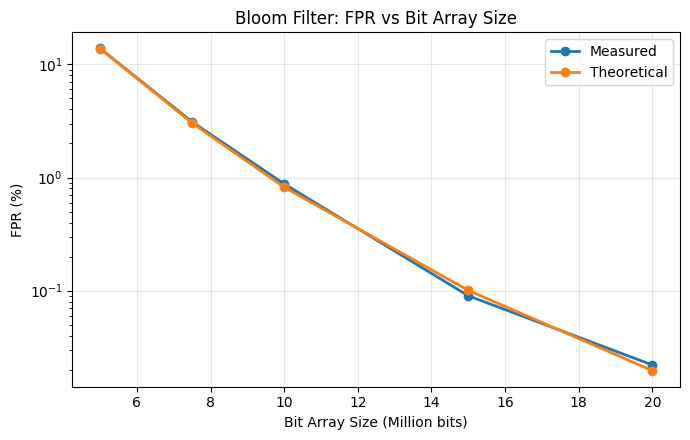

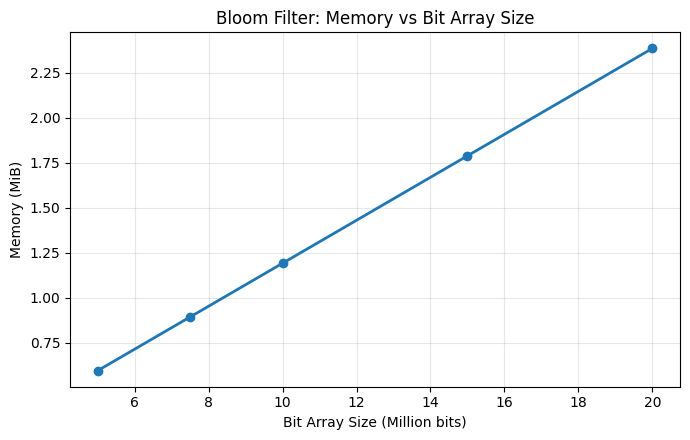

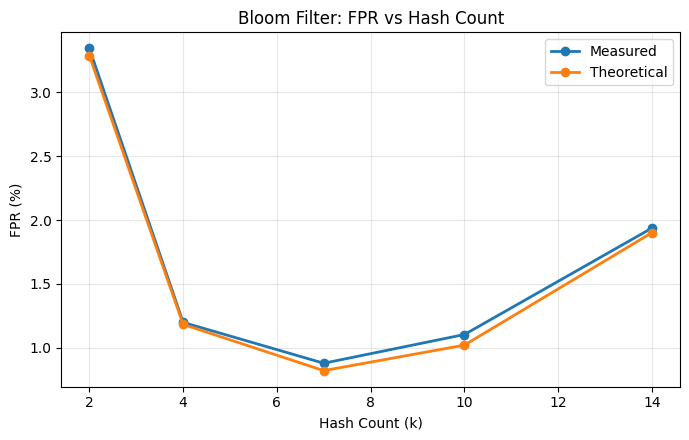

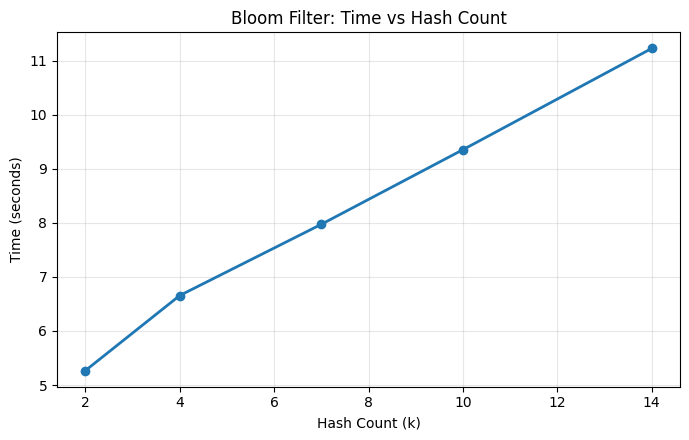

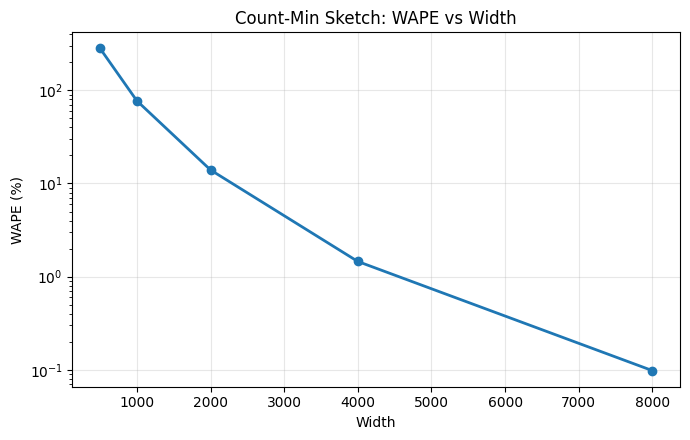

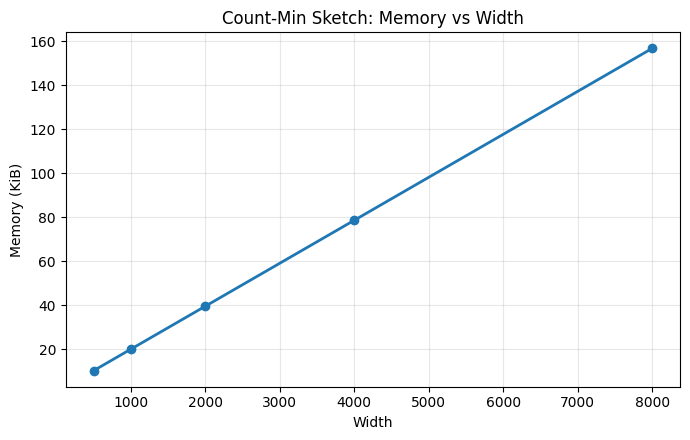

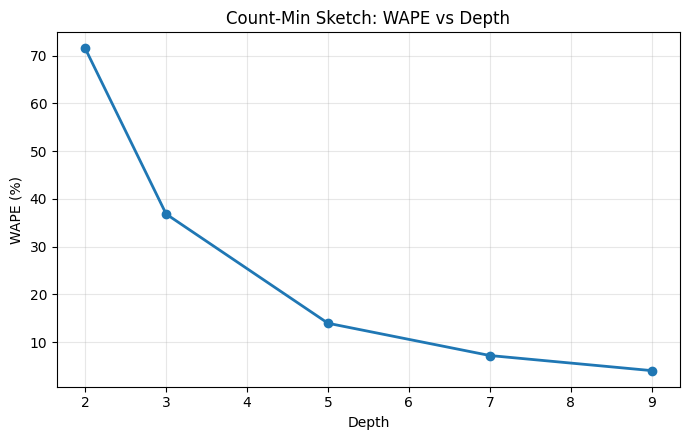

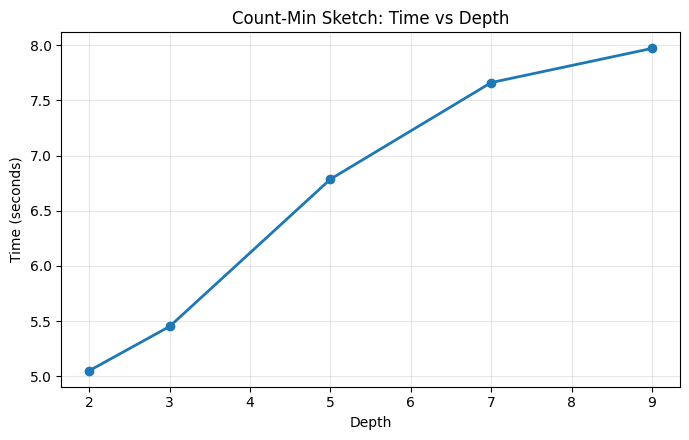

그래프 8개 저장 완료


In [22]:
# 6-1. 그래프 생성 코드
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# 그래프 저장 폴더
output_dir = Path("figures")
output_dir.mkdir(exist_ok=True)

bf_m_df = pd.DataFrame(bf_m_results)
bf_k_df = pd.DataFrame(bf_k_results)
cms_w_df = pd.DataFrame(cms_w_results)
cms_d_df = pd.DataFrame(cms_d_results)

# 공통 그래프 생성 함수
def draw_graph(df, x, y_cols, title, xlabel, ylabel,
               filename, x_div=1, log_y=False):

    plt.figure(figsize=(7, 4.5))

    for col, label in y_cols.items():
        plt.plot(
            df[x] / x_div,
            df[col],
            marker="o",
            linewidth=2,
            label=label
        )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)

    if log_y:
        plt.yscale("log")

    if len(y_cols) > 1:
        plt.legend()

    plt.tight_layout()
    plt.savefig(output_dir / filename, dpi=200)
    plt.show()
    plt.close()


# 1. Bloom Filter - m에 따른 FPR
draw_graph(
    bf_m_df, "m",
    {"FPR(%)": "Measured", "이론 FPR(%)": "Theoretical"},
    "Bloom Filter: FPR vs Bit Array Size",
    "Bit Array Size (Million bits)", "FPR (%)",
    "bf_m_fpr.png", x_div=1_000_000, log_y=True
)

# 2. Bloom Filter - m에 따른 메모리
draw_graph(
    bf_m_df, "m",
    {"메모리(MiB)": "Memory"},
    "Bloom Filter: Memory vs Bit Array Size",
    "Bit Array Size (Million bits)", "Memory (MiB)",
    "bf_m_memory.png", x_div=1_000_000
)

# 3. Bloom Filter - k에 따른 FPR
draw_graph(
    bf_k_df, "k",
    {"FPR(%)": "Measured", "이론 FPR(%)": "Theoretical"},
    "Bloom Filter: FPR vs Hash Count",
    "Hash Count (k)", "FPR (%)",
    "bf_k_fpr.png"
)

# 4. Bloom Filter - k에 따른 처리시간
draw_graph(
    bf_k_df, "k",
    {"평균시간(s)": "Processing Time"},
    "Bloom Filter: Time vs Hash Count",
    "Hash Count (k)", "Time (seconds)",
    "bf_k_time.png"
)

# 5. CMS - width에 따른 오차
draw_graph(
    cms_w_df, "width",
    {"WAPE(%)": "WAPE"},
    "Count-Min Sketch: WAPE vs Width",
    "Width", "WAPE (%)",
    "cms_width_wape.png", log_y=True
)

# 6. CMS - width에 따른 메모리
draw_graph(
    cms_w_df, "width",
    {"메모리(KiB)": "Memory"},
    "Count-Min Sketch: Memory vs Width",
    "Width", "Memory (KiB)",
    "cms_width_memory.png"
)

# 7. CMS - depth에 따른 오차
draw_graph(
    cms_d_df, "depth",
    {"WAPE(%)": "WAPE"},
    "Count-Min Sketch: WAPE vs Depth",
    "Depth", "WAPE (%)",
    "cms_depth_wape.png"
)

# 8. CMS - depth에 따른 처리시간
draw_graph(
    cms_d_df, "depth",
    {"평균시간(s)": "Processing Time"},
    "Count-Min Sketch: Time vs Depth",
    "Depth", "Time (seconds)",
    "cms_depth_time.png"
)

print("그래프 8개 저장 완료")

STEP 07. 심화 실험

In [23]:
# Bloom Filter 최적 k 비교
# 비트 배열 크기별 최적 해시 함수 개수 확인
n = len(true_pairs)

optimal_results = []

for m in [5_000_000, 7_500_000, 10_000_000,
          15_000_000, 20_000_000]:

    optimal_k = max(1, round((m / n) * math.log(2)))

    print(f"m={m:,}, 최적 k={optimal_k}")

    result = get_bloom_result(m, optimal_k)
    optimal_results.append(result)

optimal_df = pd.DataFrame(optimal_results)

display(optimal_df.round(4))

optimal_df.to_csv("bf_optimal_k_results.csv", index=False)

m=5,000,000, 최적 k=3
m=7,500,000, 최적 k=5
m=10,000,000, 최적 k=7
m=15,000,000, 최적 k=10
m=20,000,000, 최적 k=14


,m,k,FPR(%),이론 FPR(%),메모리(MiB),평균시간(s),처리량(건/s)
0,5000000,3,9.199,9.1891,0.5961,5.8678,170457.2140
1,7500000,5,2.641,2.7296,0.8941,7.0923,141028.4087
2,10000000,7,0.878,0.8202,1.1921,7.9738,125436.8585
3,15000000,10,0.085,0.0745,1.7882,9.4288,106080.0323
4,20000000,14,0.009,0.0067,2.3842,11.2926,88572.0094


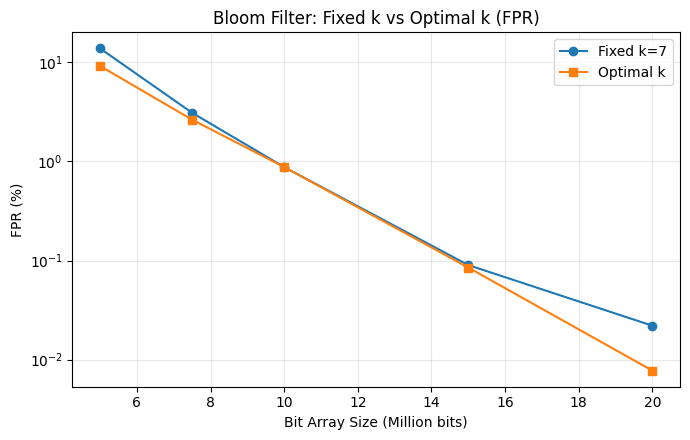

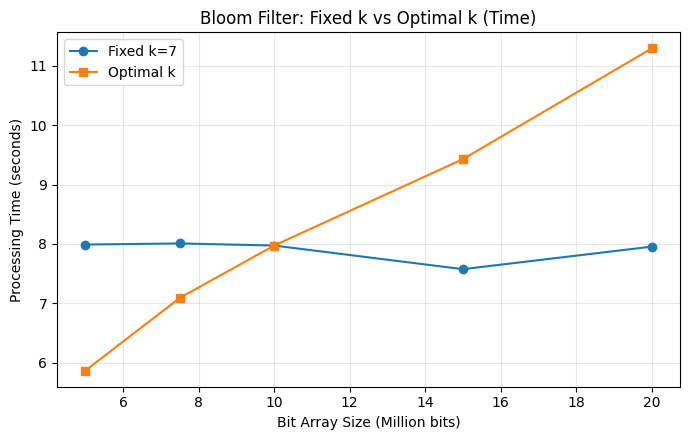

심화 실험 그래프 2개 저장 완료


In [24]:
# 심화 실험 결과 그래프
fixed_df = pd.DataFrame(bf_m_results)
optimal_df = pd.DataFrame(optimal_results)

# 9. 고정 k와 최적 k의 FPR 비교
plt.figure(figsize=(7, 4.5))

plt.plot(
    fixed_df["m"] / 1_000_000,
    fixed_df["FPR(%)"],
    marker="o", label="Fixed k=7"
)

plt.plot(
    optimal_df["m"] / 1_000_000,
    optimal_df["FPR(%)"],
    marker="s", label="Optimal k"
)

plt.title("Bloom Filter: Fixed k vs Optimal k (FPR)")
plt.xlabel("Bit Array Size (Million bits)")
plt.ylabel("FPR (%)")
plt.yscale("symlog", linthresh=0.01)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figures/bf_optimal_k_fpr.png", dpi=200)
plt.show()
plt.close()


# 10. 고정 k와 최적 k의 처리시간 비교
plt.figure(figsize=(7, 4.5))

plt.plot(
    fixed_df["m"] / 1_000_000,
    fixed_df["평균시간(s)"],
    marker="o", label="Fixed k=7"
)

plt.plot(
    optimal_df["m"] / 1_000_000,
    optimal_df["평균시간(s)"],
    marker="s", label="Optimal k"
)

plt.title("Bloom Filter: Fixed k vs Optimal k (Time)")
plt.xlabel("Bit Array Size (Million bits)")
plt.ylabel("Processing Time (seconds)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figures/bf_optimal_k_time.png", dpi=200)
plt.show()
plt.close()

print("심화 실험 그래프 2개 저장 완료")

In [25]:
# STEP 08. 전체 그래프 다운로드
import shutil
from google.colab import files

# 기본 그래프 8개 + 심화 실험 그래프 2개
shutil.make_archive("experiment_figures", "zip", "figures")

files.download("experiment_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>